In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import tqdm.auto as tqdm
from urllib.request import urlretrieve

In [3]:
data = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"


urlretrieve(url=data, filename='course_lead_scoring_2026.csv')

('course_lead_scoring_2026.csv', <http.client.HTTPMessage at 0x21c4915daf0>)

In [2]:
df = pd.read_csv('course_lead_scoring_2026.csv')

df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   object 
 1   industry                  4760 non-null   object 
 2   employment_status         4806 non-null   object 
 3   location                  4792 non-null   object 
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 351.7+ KB


In [4]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

converted
1    0.5766
0    0.4234
Name: proportion, dtype: float64


<Axes: xlabel='converted', ylabel='Count'>

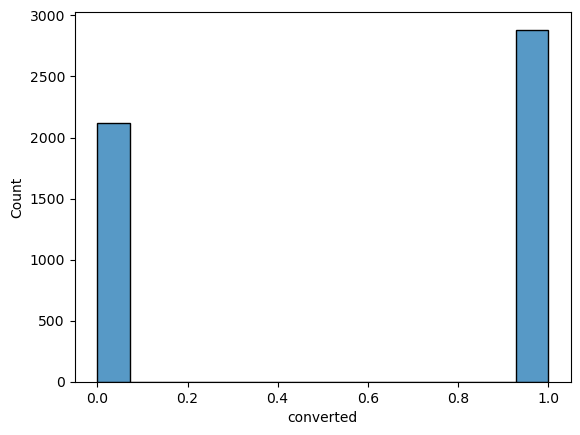

In [5]:
print(df.converted.value_counts(normalize=True))


sns.histplot(df['converted'])

In [6]:
df.columns

Index(['lead_source', 'industry', 'employment_status', 'location',
       'annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score', 'converted'],
      dtype='object')

In [7]:
df = df.fillna(0)

In [8]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)

df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

In [9]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)
df_full_train = df_full_train.reset_index(drop=True)

In [10]:
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

In [11]:
len(df_test), len(df_full_train), len(df_val)

(1000, 4000, 1000)

In [12]:
categorical = list(df_train.dtypes[df_train.dtypes == 'object'].index)
numerical = list(df_train.dtypes[df_train.dtypes != 'object'].index)

In [13]:
numerical.pop(-1)

'converted'

In [14]:
df_full_train[categorical].nunique()

lead_source          6
industry             7
employment_status    5
location             6
dtype: int64

### Question 1

In [15]:
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression


In [16]:
scores = []
for num_var in numerical:
    scores.append(roc_auc_score(df_train['converted'], df_train[num_var]))

for name,score in zip(numerical, scores):
    print(name, score, sep=' ')


annual_income 0.6081977776250831
number_of_courses_viewed 0.7229894623989618
interaction_count 0.7649203047563227
lead_score 0.7882254810906102


### Question 2: Training the model


In [17]:
del df_train['converted']
del df_val['converted']

In [18]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient = 'records')

    dv = DictVectorizer(sparse=False)

    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)

    return dv, model

In [19]:
def predict(df,dv,model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [20]:
dv, model = train(df_train, y_train)
y_pred = predict(df_val, dv, model)

In [21]:
### AUC
round(roc_auc_score(y_val, y_pred), 3)

0.732

In [22]:
actual_positive = (y_val == 1)
actual_negative = (y_val == 0)

t = 0.5

pred_pos = (y_pred >= t)
pred_neg = (y_pred < t)


tp = (pred_pos & actual_positive).sum()
tn = (pred_neg & actual_negative).sum()

fp = (pred_pos & actual_negative).sum()
fn = (pred_neg & actual_positive).sum()

In [23]:
tp, tn, fp, fn

(np.int64(530), np.int64(120), np.int64(294), np.int64(56))

In [24]:
confusion_matrix = np.array([
    [tn, fp],
    [fn, tp]
])

confusion_matrix

array([[120, 294],
       [ 56, 530]])

In [25]:
precision = tp / (fp + tp)
precision

np.float64(0.6432038834951457)

In [26]:
recall = tp / (fn + tp)
recall

np.float64(0.9044368600682594)

- Various Thresholds

In [27]:
def compute_P_R(t):
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)

    pred_pos = (y_pred >= t)
    pred_neg = (y_pred < t)


    tp = (pred_pos & actual_positive).sum()
    tn = (pred_neg & actual_negative).sum()

    fp = (pred_pos & actual_negative).sum()
    fn = (pred_neg & actual_positive).sum()

    precision = tp / (fp + tp)
    recall = tp / (fn + tp)
    return precision, recall

    

In [28]:
thresholds = np.arange(0.0, 1.0, 0.01)
scores = {}

for t in thresholds:
    precision, recall = compute_P_R(t)

    scores[t] = (precision, recall)



C:\Users\Samuel\AppData\Local\Temp\ipykernel_16572\1150922649.py:15: RuntimeWarning: invalid value encountered in scalar divide
  precision = tp / (fp + tp)


<Axes: >

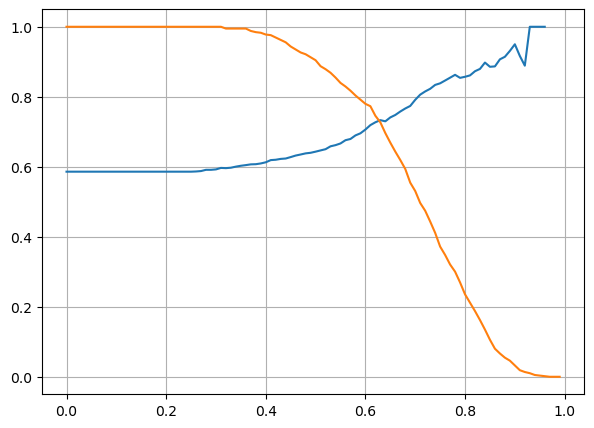

In [29]:
precisions = [scores[t][0] for t in scores]
recalls = [scores[t][1] for t in scores]


plt.figure(figsize=(7, 5))
plt.grid()
sns.lineplot(x = thresholds, y = precisions)
sns.lineplot(x = thresholds, y = recalls)


In [30]:
df_scores = pd.DataFrame(scores, index=['precision', 'recall'])
df_scores = df_scores.T
df_scores

,precision,recall
0.00,0.586,1.000000
0.01,0.586,1.000000
0.02,0.586,1.000000
0.03,0.586,1.000000
0.04,0.586,1.000000
...,...,...
0.95,1.000,0.003413
0.96,1.000,0.001706
0.97,NaN,0.000000
0.98,NaN,0.000000


### Q4

In [31]:
def compute_F1 (row):
    return 2 * (row["precision"]*row["recall"])/(row["precision"]+row["recall"])


df_scores['F1'] = df_scores.apply(compute_F1, axis=1)

df_scores

,precision,recall,F1
0.00,0.586,1.000000,0.738966
0.01,0.586,1.000000,0.738966
0.02,0.586,1.000000,0.738966
0.03,0.586,1.000000,0.738966
0.04,0.586,1.000000,0.738966
...,...,...,...
0.95,1.000,0.003413,0.006803
0.96,1.000,0.001706,0.003407
0.97,NaN,0.000000,NaN
0.98,NaN,0.000000,NaN


0.7576158940397352


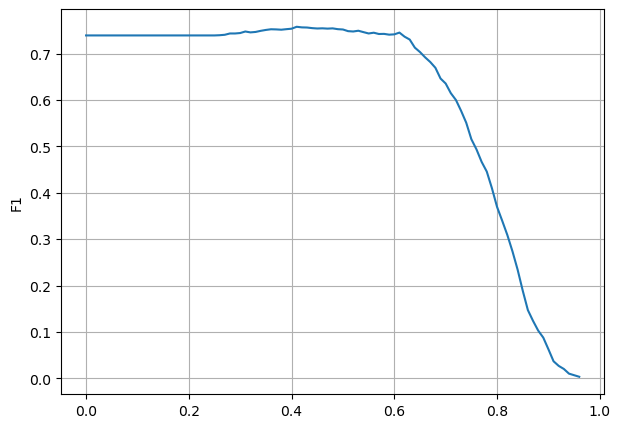

In [32]:
plt.figure(figsize=(7, 5))
plt.grid()
sns.lineplot(x = thresholds, y = df_scores["F1"])

print(df_scores['F1'].max())

### Question 5: 5-Fold CV


In [33]:
from sklearn.model_selection import KFold
from tqdm.auto import tqdm

n_splits = 5

In [34]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)
scores=[]
for train_idx, val_idx in tqdm(kfold.split(df_full_train)):
    
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train['converted'].values
    y_val = df_val['converted'].values

    dv, model = train(df_train, y_train)
    y_pred = predict(df_val, dv, model)

    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)
        
    print('%.3f +- %.3f' % (np.mean(scores), np.std(scores)))

0it [00:00, ?it/s]

0.731 +- 0.000
0.730 +- 0.000
0.732 +- 0.003
0.734 +- 0.005
0.732 +- 0.007


### Q6

In [36]:
for C in tqdm([0.000001, 0.001, 1]):
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train['converted'].values
        y_val = df_val['converted'].values

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)
        
    print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

  0%|          | 0/3 [00:00<?, ?it/s]

C=1e-06 0.617 +- 0.019
C=0.001 0.749 +- 0.010
C=1 0.732 +- 0.007


In [ ]:
``aaaaaa

SyntaxError: invalid syntax (1332110921.py, line 1)